In [67]:
# import des bibliothèques nécessaires
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


In [68]:
# Récupération du dataset
df = pd.read_csv('data/df_clean.csv')
df.head()

,OSEBuildingID,BuildingType,PrimaryPropertyType,PropertyName,Address,TaxParcelIdentificationNumber,CouncilDistrictCode,Neighborhood,Latitude,Longitude,...,SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
0,1,NonResidential,Hotel,Mayflower park hotel,405 Olive way,0659000030,7,DOWNTOWN,47.61220,-122.33799,...,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,249.98,2.83
1,2,NonResidential,Hotel,Paramount Hotel,724 Pine street,0659000220,7,DOWNTOWN,47.61317,-122.33393,...,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,295.86,2.86
2,3,NonResidential,Hotel,5673-The Westin Seattle,1900 5th Avenue,0659000475,7,DOWNTOWN,47.61393,-122.33810,...,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,2089.28,2.19
3,5,NonResidential,Hotel,HOTEL MAX,620 STEWART ST,0659000640,7,DOWNTOWN,47.61412,-122.33664,...,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,286.43,4.67
4,8,NonResidential,Hotel,WARWICK SEATTLE HOTEL (ID8),401 LENORA ST,0659000970,7,DOWNTOWN,47.61375,-122.34047,...,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,505.01,2.88


# Exploration du dataset nettoyé

In [69]:
# information sur les données et les types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1542 entries, 0 to 1541
Data columns (total 37 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   OSEBuildingID                    1542 non-null   int64  
 1   BuildingType                     1542 non-null   str    
 2   PrimaryPropertyType              1542 non-null   str    
 3   PropertyName                     1542 non-null   str    
 4   Address                          1542 non-null   str    
 5   TaxParcelIdentificationNumber    1542 non-null   str    
 6   CouncilDistrictCode              1542 non-null   int64  
 7   Neighborhood                     1542 non-null   str    
 8   Latitude                         1542 non-null   float64
 9   Longitude                        1542 non-null   float64
 10  YearBuilt                        1542 non-null   int64  
 11  NumberofBuildings                1542 non-null   float64
 12  NumberofFloors                 

In [70]:
# Informations statistiques sur les colonnes numériques

df.describe()

,OSEBuildingID,CouncilDistrictCode,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFATotal,PropertyGFAParking,PropertyGFABuilding(s),...,SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
count,1542.000000,1542.000000,1542.000000,1542.000000,1542.000000,1542.000000,1526.000000,1.542000e+03,1542.000000,1.542000e+03,...,1542.000000,1.542000e+03,1.541000e+03,1.542000e+03,1.542000e+03,1.542000e+03,1.542000e+03,1.542000e+03,1542.000000,1542.000000
mean,16470.426719,4.415045,47.616487,-122.333523,1961.588846,1.142023,4.262123,1.152784e+05,13872.791829,1.014056e+05,...,185.607588,8.024914e+06,8.156507e+06,4.982141e+05,1.652264e+06,5.637525e+06,1.852867e+04,1.852867e+06,176.163366,1.650415
std,13789.438674,2.192603,0.046978,0.023265,32.838734,1.182804,6.368218,1.978206e+05,43796.081781,1.753431e+05,...,188.065920,1.928942e+07,1.952623e+07,5.310227e+06,3.885019e+06,1.325569e+07,6.148985e+04,6.148985e+06,592.219483,2.265110
min,1.000000,1.000000,47.509590,-122.411820,1900.000000,1.000000,1.000000,1.128500e+04,0.000000,3.636000e+03,...,0.000000,5.713320e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.400000,0.010000
25%,602.250000,2.000000,47.587825,-122.343093,1930.000000,1.000000,1.000000,2.882525e+04,0.000000,2.791425e+04,...,84.674999,1.248602e+06,1.322417e+06,0.000000e+00,2.144374e+05,7.316600e+05,0.000000e+00,0.000000e+00,20.685000,0.360000
50%,21180.500000,4.000000,47.612615,-122.333170,1965.000000,1.000000,2.000000,4.806600e+04,0.000000,4.602500e+04,...,141.849998,2.727768e+06,2.824097e+06,0.000000e+00,5.109501e+05,1.743362e+06,4.910975e+03,4.910975e+05,49.940000,0.885000
75%,24603.750000,7.000000,47.649080,-122.322823,1988.000000,1.000000,4.000000,1.073940e+05,0.000000,9.530650e+04,...,215.674999,7.271161e+06,7.456910e+06,0.000000e+00,1.542024e+06,5.261384e+06,1.531061e+04,1.531061e+06,147.105000,1.960000
max,50226.000000,7.000000,47.733870,-122.261800,2015.000000,27.000000,76.000000,2.200000e+06,512608.000000,2.200000e+06,...,2620.000000,2.930908e+08,2.966717e+08,1.349435e+08,8.046087e+07,2.745325e+08,1.381912e+06,1.381912e+08,12307.160000,25.710000


In [71]:
# Informations sur les colonnes non numériques

df.describe(exclude=[np.number])

,BuildingType,PrimaryPropertyType,PropertyName,Address,TaxParcelIdentificationNumber,Neighborhood,ListOfAllPropertyUseTypes,LargestPropertyUseType,SecondLargestPropertyUseType,ThirdLargestPropertyUseType
count,1542,1542,1542,1542,1542,1542,1542,1542,1542,1542
unique,5,20,1538,1521,1463,13,366,55,48,40
top,NonResidential,Small- and Mid-Sized Office,South Park,2600 SW Barton St,1625049001,DOWNTOWN,Office,Office,Aucun,Aucun
freq,1429,285,2,4,7,350,131,484,703,1197



ListOfAllPropertyUseTypes est comme son nom l'indique, une liste. 
Sachant que certaines informations de cette liste sont reprise dans les colonnes LargestPropertyUseType/SecondLargestPropertyUseType/ThirdLargestPropertyUseType, on peut modifier la liste en colonne numérique en la remplacant pas le nombre de types dans la liste 

In [72]:
# Remplacement de la liste par le nombre de types
df["ListOfAllPropertyUseTypes"] = df["ListOfAllPropertyUseTypes"].apply(lambda x : len(x.split(",")))

On retrouve des colonnes avec une forte cardinalité, c'est à dire avec quasiment autant de valeurs uniques que de lignes. 

Ce sont des colonnes identifiantes mais qui n'apportent pas d'intéret prédictive pour le modèle. 
En règle générale, il est préférable de supprimer les colonnes qui sont uniquement identifiantes et qui ne possèdent pas de réelle valeur prédictive.

In [73]:
# Suppression des colonnes à forte cardinalité
df = df.drop(columns = ["PropertyName","Address","TaxParcelIdentificationNumber"])

df.head()


,OSEBuildingID,BuildingType,PrimaryPropertyType,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,...,SourceEUIWN(kBtu/sf),SiteEnergyUse(kBtu),SiteEnergyUseWN(kBtu),SteamUse(kBtu),Electricity(kWh),Electricity(kBtu),NaturalGas(therms),NaturalGas(kBtu),TotalGHGEmissions,GHGEmissionsIntensity
0,1,NonResidential,Hotel,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,...,189.000000,7226362.5,7456910.0,2003882.00,1.156514e+06,3946027.0,12764.52930,1276453.0,249.98,2.83
1,2,NonResidential,Hotel,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,...,179.399994,8387933.0,8664479.0,0.00,9.504252e+05,3242851.0,51450.81641,5145082.0,295.86,2.86
2,3,NonResidential,Hotel,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,...,244.100006,72587024.0,73937112.0,21566554.00,1.451544e+07,49526664.0,14938.00000,1493800.0,2089.28,2.19
3,5,NonResidential,Hotel,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,...,224.000000,6794584.0,6946800.5,2214446.25,8.115253e+05,2768924.0,18112.13086,1811213.0,286.43,4.67
4,8,NonResidential,Hotel,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,...,215.600006,14172606.0,14656503.0,0.00,1.573449e+06,5368607.0,88039.98438,8803998.0,505.01,2.88


les information qu'on ne pourra pas avoir sans relevés détaillés des propriétés 
On ne veut pas entraîner nos modèles dessus car on n'aura pas ces informations --> à drop:

 SiteEUI(kBtu/sf) -
  SiteEUIWN(kBtu/sf) -
 SourceEUI(kBtu/sf) -
 SourceEUIWN(kBtu/sf) -
 SiteEnergyUseWN(kBtu) -
 SteamUse(kBtu) -
 Electricity(kWh) -
 Electricity(kBtu) -
 NaturalGas(therms) -
 NaturalGas(kBtu) -              
 GHGEmissionsIntensity          



In [74]:
# Suppression des colonnes ayant de l'information énergétique : 
df = df.drop(columns=['SiteEUI(kBtu/sf)','SiteEUIWN(kBtu/sf)','SiteEnergyUseWN(kBtu)', 'SourceEUI(kBtu/sf)', 'SourceEUIWN(kBtu/sf)', 'GHGEmissionsIntensity','SteamUse(kBtu)','Electricity(kWh)', 'Electricity(kBtu)','NaturalGas(therms)','NaturalGas(kBtu)'])

df.head()

,OSEBuildingID,BuildingType,PrimaryPropertyType,CouncilDistrictCode,Neighborhood,Latitude,Longitude,YearBuilt,NumberofBuildings,NumberofFloors,...,ListOfAllPropertyUseTypes,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
0,1,NonResidential,Hotel,7,DOWNTOWN,47.61220,-122.33799,1927,1.0,12.0,...,1,Hotel,88434.0,Aucun,0.0,Aucun,0.0,60.0,7226362.5,249.98
1,2,NonResidential,Hotel,7,DOWNTOWN,47.61317,-122.33393,1996,1.0,11.0,...,3,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.0,295.86
2,3,NonResidential,Hotel,7,DOWNTOWN,47.61393,-122.33810,1969,1.0,41.0,...,1,Hotel,756493.0,Aucun,0.0,Aucun,0.0,43.0,72587024.0,2089.28
3,5,NonResidential,Hotel,7,DOWNTOWN,47.61412,-122.33664,1926,1.0,10.0,...,1,Hotel,61320.0,Aucun,0.0,Aucun,0.0,56.0,6794584.0,286.43
4,8,NonResidential,Hotel,7,DOWNTOWN,47.61375,-122.34047,1980,1.0,18.0,...,3,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.0,505.01


<Axes: >

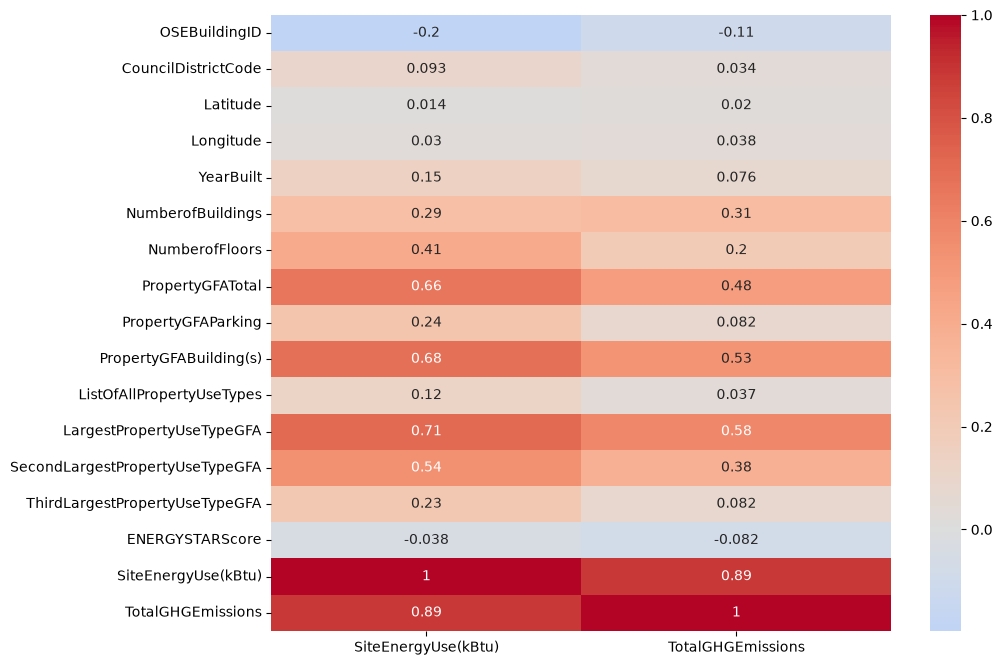

In [75]:
# détermination de la corrélation entre les colonnes numériques et les colonnes SiteEnergyUse(kBtu) et TotalGHGEmissions

corr_matrix = df.select_dtypes(include=['float64', 'int64']).corr()[['SiteEnergyUse(kBtu)','TotalGHGEmissions']]

# Visualisation de la corrélation
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)

Colonnes avec une corrélation modérée à forte (>0.4) avec SiteEnergyUse(kBtu): 

    - (NumberOfBuildings)
    - (NumberOfFloors)
    - PropertyGFATotal
    - PropertyGFABuilding(s)
    - LargestPropertyUseTypeGFA
    - SecondLargestPropertyUseTypeGFA
    - (ThirdLargestPropertyUseTypeGFA)

(entre parenthèses --> éventuellement à supprimer pour voir si cela améliore le modèle)

TotalGHGEEmissions et SiteEnergyUse sont les cibles à prédire donc on ne les prends pas en compte.

Le ENERGYSTARScore n'a pas une corrélation importante mais le but est aussi de voir son importance alors on peu la garder pour l'instant

Le YearBuilt a une faible corrélation car il s'agit on recherche une consommation d'énergie et émissions totales, et non pas par rapport à la surface des bâtiments. Sachant que nous avons dans notre dataset également la surface, il peut être intéressant de garder cette colonne pour voir son influence

PropertyGFATotal concerne les bâtiments et les parkings, et PropertyGFABuilding(s) uniquement les bâtiments. Sachant que les parkings ne consomment pas beaucoup d'énergie et présentent une corrélation faible, et que PropertyGFABuilding(s) et PropertyGFATotal sont donc très proches, il serait judicieux de n'en garder qu'une des 2 pour éviter le phénomène de multicolinéarité

Malgré la transformation ListOfAllPropertyUseTypes, il ne semble pas y avoir de corrélation entre cette colonnes et nos cibles


In [76]:
columns_to_drop = [
    "OSEBuildingID",
    "CouncilDistrictCode",
    "Latitude",
    "Longitude",
    "PropertyGFATotal",
    "PropertyGFAParking",
    "ListOfAllPropertyUseTypes"
]

df = df.drop(columns=columns_to_drop)

df.head()

,BuildingType,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
0,NonResidential,Hotel,DOWNTOWN,1927,1.0,12.0,88434,Hotel,88434.0,Aucun,0.0,Aucun,0.0,60.0,7226362.5,249.98
1,NonResidential,Hotel,DOWNTOWN,1996,1.0,11.0,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.0,295.86
2,NonResidential,Hotel,DOWNTOWN,1969,1.0,41.0,759392,Hotel,756493.0,Aucun,0.0,Aucun,0.0,43.0,72587024.0,2089.28
3,NonResidential,Hotel,DOWNTOWN,1926,1.0,10.0,61320,Hotel,61320.0,Aucun,0.0,Aucun,0.0,56.0,6794584.0,286.43
4,NonResidential,Hotel,DOWNTOWN,1980,1.0,18.0,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.0,505.01


# Visualisations

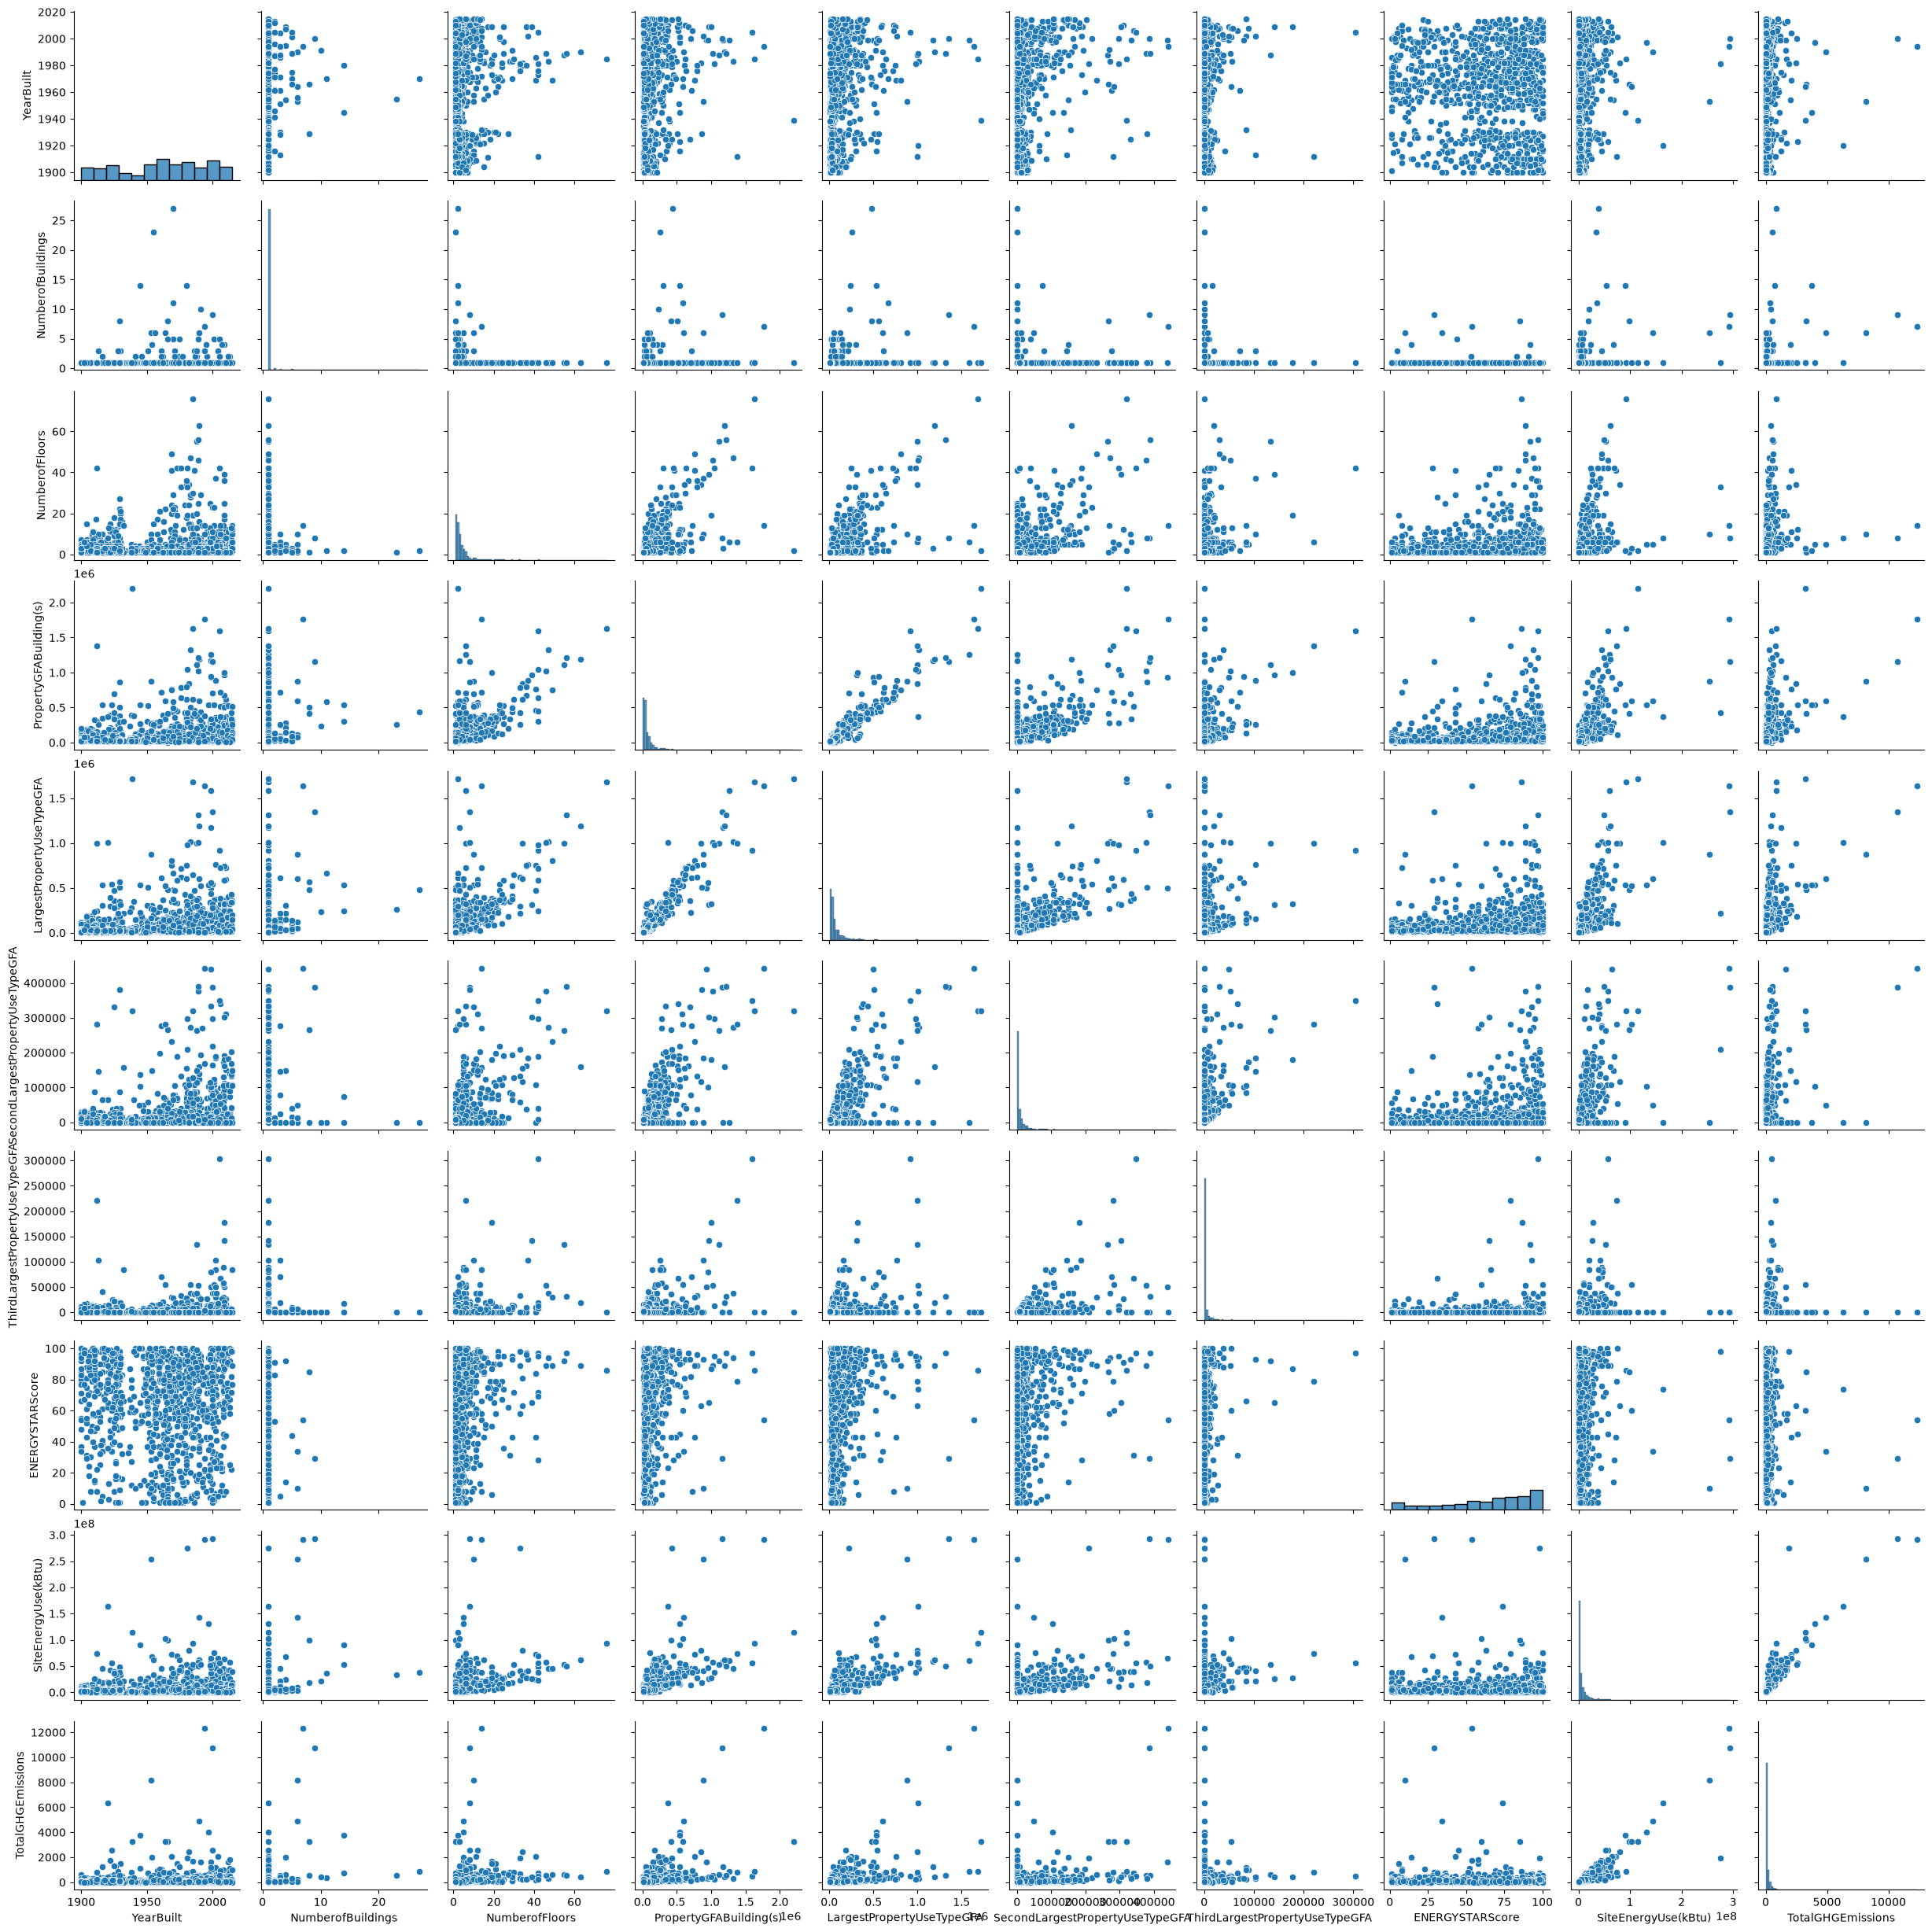

In [77]:
# Visualisations des relations des valeurs numérques dans notre df

sns.pairplot(df)

plt.show()

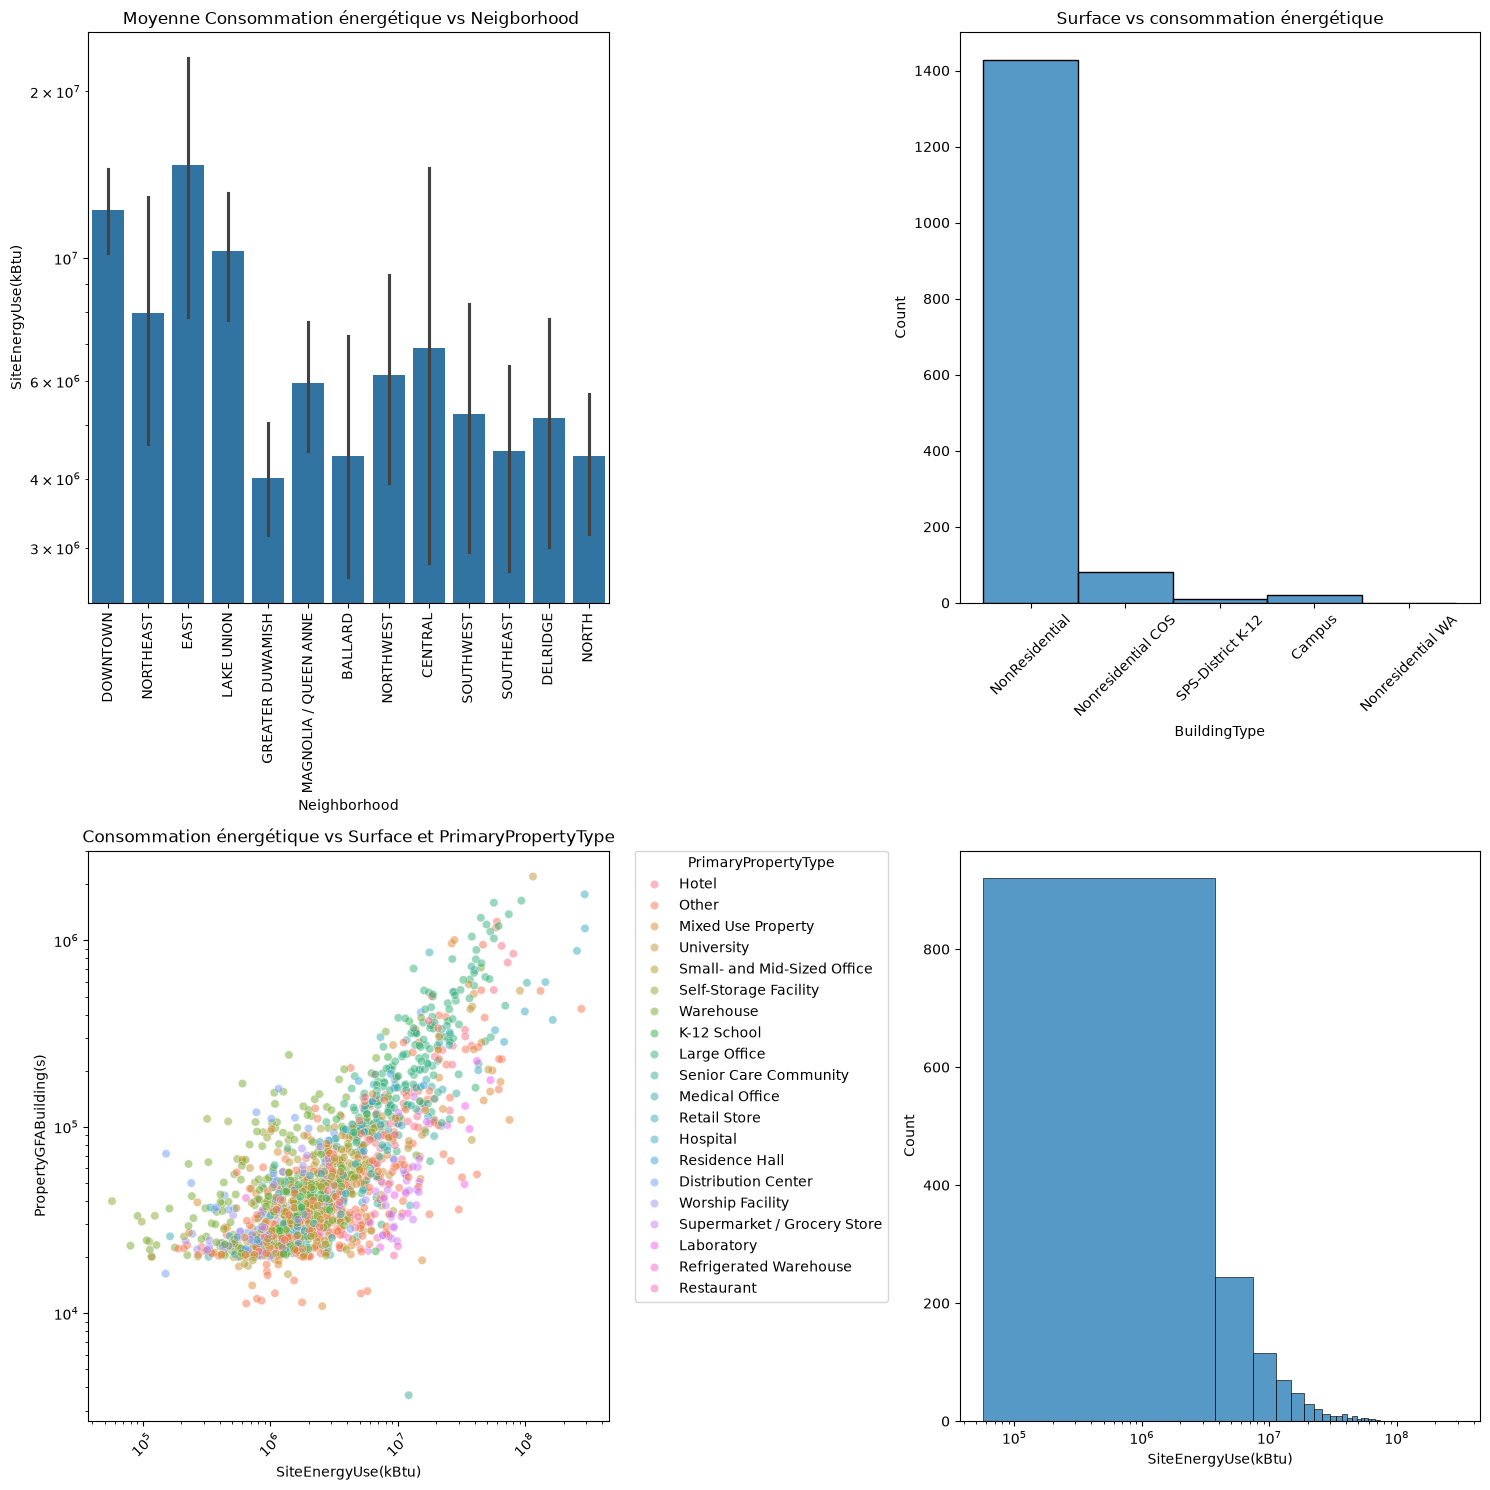

In [78]:
fig, axes = plt.subplots(2, 2, figsize=(15, 15))

# Graphique 1 : Consommation énergétique selon la localisation géographique
sns.barplot(data = df, x = 'Neighborhood',y = 'SiteEnergyUse(kBtu)', ax = axes[0,0])
axes[0,0].set_yscale('log')
axes[0, 0].set_title(' Moyenne Consommation énergétique vs Neigborhood')

# Graphique 2 : Distribution des building types
sns.histplot(data=df,x='BuildingType',ax=axes[0, 1])
axes[0, 1].set_title('Building types')
axes[0, 1].set_title('Surface vs consommation énergétique')

# Graphique 3 : Energie, surface et Type de batiment
sns.scatterplot(data=df,x='SiteEnergyUse(kBtu)',y='PropertyGFABuilding(s)',hue = 'PrimaryPropertyType',ax=axes[1, 0],alpha=0.5)
axes[1, 0].set_xscale('log')
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Consommation énergétique vs Surface et PrimaryPropertyType')
axes[1, 0].legend(title='PrimaryPropertyType',bbox_to_anchor=(1.05, 1),loc='upper left',borderaxespad=0)

# Graphique 4 : Energie, surface et Type de batiment
sns.histplot(data=df,x='SiteEnergyUse(kBtu)',ax=axes[1, 1])
axes[1, 1].set_xscale('log')

axes[0, 0].tick_params(axis='x', labelrotation=90)
axes[0, 1].tick_params(axis='x', labelrotation=45)
axes[1, 0].tick_params(axis='x', labelrotation=45)

plt.tight_layout()
plt.show()

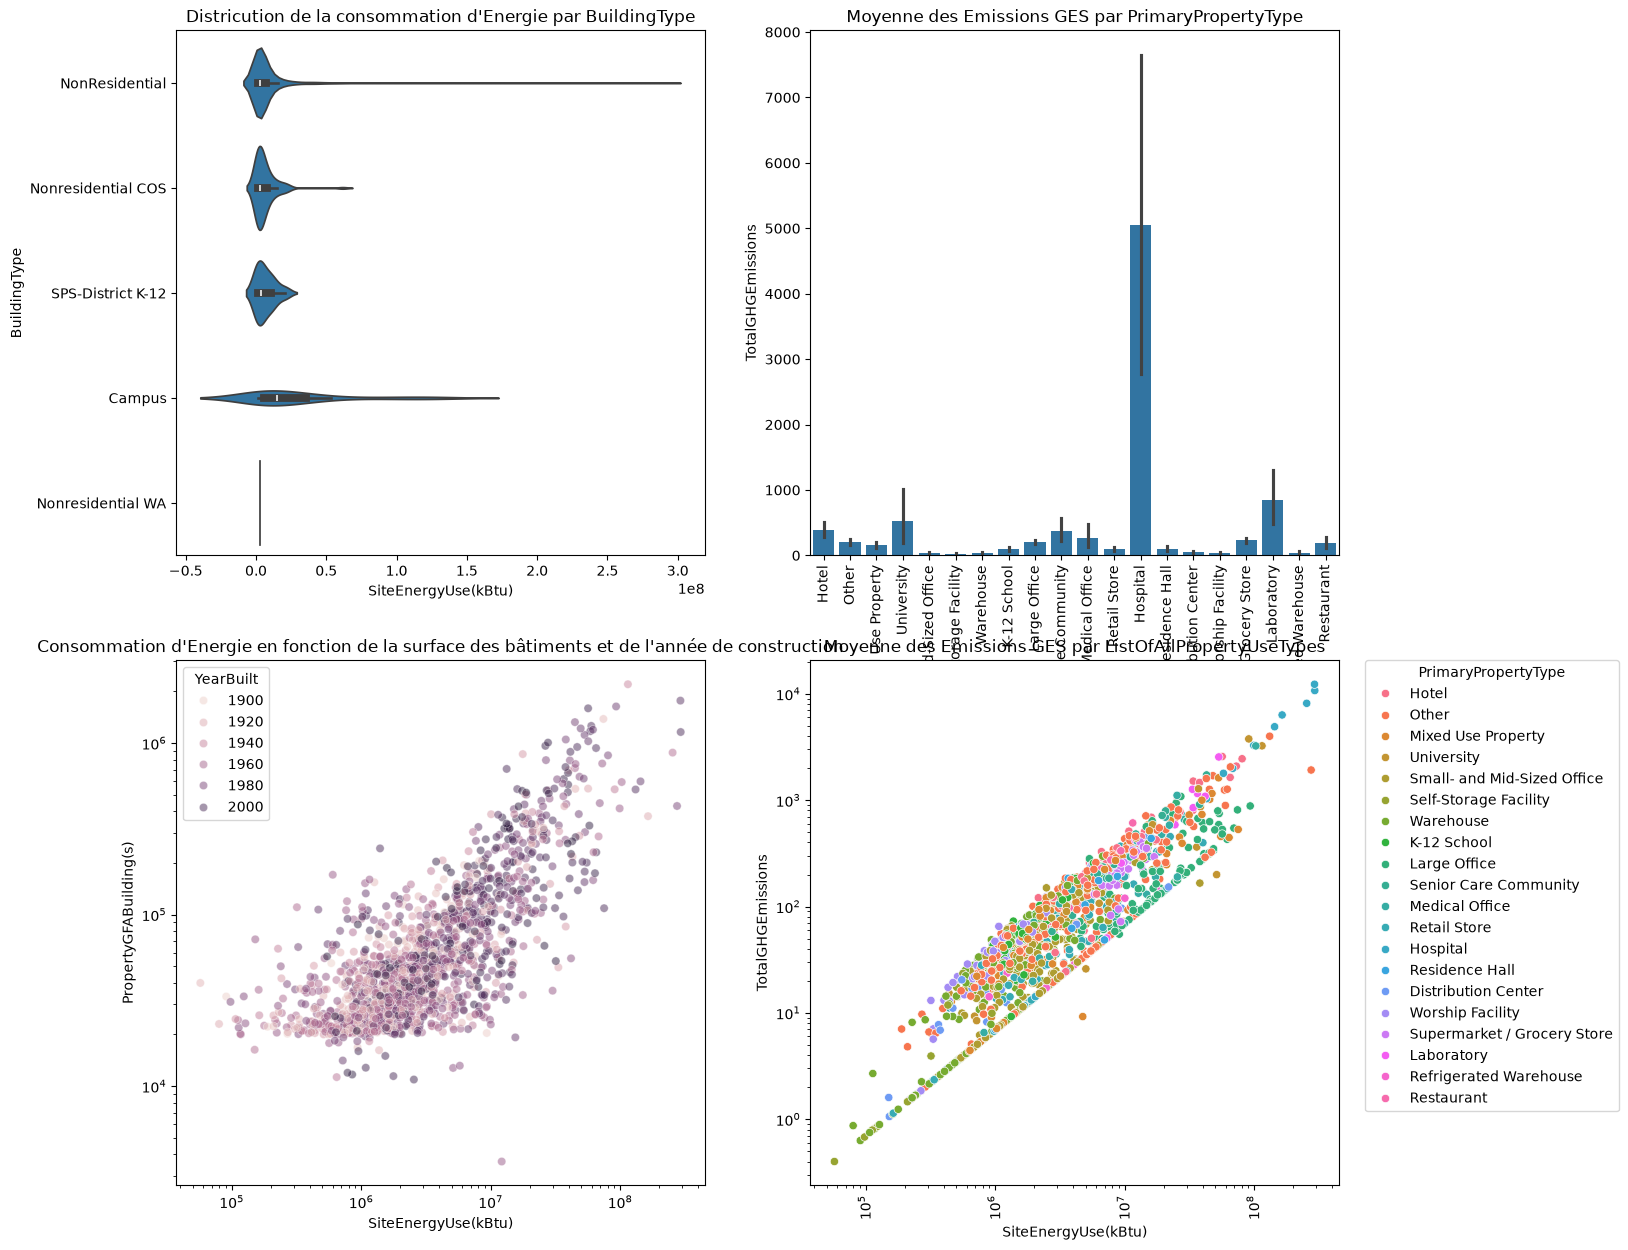

In [79]:
fig, axes = plt.subplots(2, 2, figsize=(15, 15))

sns.violinplot(data=df, x = 'SiteEnergyUse(kBtu)' , y= 'BuildingType', ax=axes[0, 0] )
axes[0,0].set_title("Districution de la consommation d'Energie par BuildingType")

sns.barplot(data=df, x = 'PrimaryPropertyType' , y = 'TotalGHGEmissions', ax=axes[0, 1] )
axes[0, 1].tick_params(axis='x', labelrotation=90)
axes[0,1].set_title("Moyenne des Emissions GES par PrimaryPropertyType")

sns.scatterplot(data=df, x = 'SiteEnergyUse(kBtu)' , y = 'PropertyGFABuilding(s)', hue = 'YearBuilt', alpha = 0.5, ax=axes[1,0])
axes[1,0].set_title("Consommation d'Energie en fonction de la surface des bâtiments et de l'année de construction")
axes[1,0].set_xscale('log')
axes[1,0].set_yscale('log')

sns.scatterplot(data=df, x = 'SiteEnergyUse(kBtu)' , y = 'TotalGHGEmissions',hue = "PrimaryPropertyType", ax=axes[1, 1] )
axes[1,1].tick_params(axis='x', labelrotation=90)
axes[1,1].set_title("Moyenne des Emissions GES par ListOfAllPropertyUseTypes")
axes[1,1].set_yscale('log')
axes[1,1].set_xscale('log')
axes[1,1].legend(title='PrimaryPropertyType',bbox_to_anchor=(1.05, 1),loc='upper left',borderaxespad=0)

In [80]:
# Visualisation des données où le nombre d'étages n'est pas renseigné

df[df['NumberofFloors'].isna() == True]

,BuildingType,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
129,NonResidential,Hotel,DOWNTOWN,1999,1.0,NaN,934292,Hotel,495536.0,Parking,438756.0,Restaurant,49700.0,NaN,6.504728e+07,1638.46
430,NonResidential,Medical Office,EAST,2004,1.0,NaN,225982,Medical Office,200184.0,Aucun,0.0,Aucun,0.0,53.0,2.056062e+07,692.12
431,NonResidential,Mixed Use Property,DOWNTOWN,2006,1.0,NaN,516407,Parking,385196.0,Multifamily Housing,340236.0,Hotel,67627.0,31.0,3.940332e+07,734.72
502,NonResidential,Other,DOWNTOWN,1999,1.0,NaN,947987,Other - Mall,561684.0,Other - Entertainment/Public Assembly,100000.0,Restaurant,80000.0,NaN,4.651096e+07,324.25
863,NonResidential,Worship Facility,GREATER DUWAMISH,1977,1.0,NaN,21948,Worship Facility,21948.0,Aucun,0.0,Aucun,0.0,80.0,3.260012e+05,2.27
990,NonResidential,Medical Office,EAST,1945,1.0,NaN,274568,Medical Office,228133.0,Parking,135954.0,Aucun,0.0,52.0,2.531153e+07,1110.07
1070,Campus,Other,GREATER DUWAMISH,1991,10.0,NaN,230971,Other,230970.0,Parking,0.0,Aucun,0.0,NaN,2.102229e+07,405.05
1454,NonResidential,Warehouse,NORTHEAST,1940,1.0,NaN,384772,Non-Refrigerated Warehouse,349953.0,Office,63872.0,Aucun,0.0,69.0,1.520676e+07,391.70
1455,NonResidential,Medical Office,NORTHEAST,1960,1.0,NaN,30287,Medical Office,28050.0,Aucun,0.0,Aucun,0.0,32.0,2.193115e+06,32.72
1456,NonResidential,Small- and Mid-Sized Office,NORTHEAST,1960,1.0,NaN,21931,Office,31845.0,Office,31845.0,Aucun,0.0,32.0,3.947209e+06,145.11


In [81]:
# Récupération des médians par PrimaryPropertyType
df.groupby("PrimaryPropertyType")["NumberofFloors"].median()

PrimaryPropertyType
Distribution Center            1.0
Hospital                       7.5
Hotel                          7.0
K-12 School                    2.0
Laboratory                     4.0
Large Office                   8.0
Medical Office                 3.0
Mixed Use Property             2.0
Other                          2.0
Refrigerated Warehouse         1.0
Residence Hall                 3.0
Restaurant                     2.5
Retail Store                   2.0
Self-Storage Facility          2.0
Senior Care Community          3.0
Small- and Mid-Sized Office    3.0
Supermarket / Grocery Store    1.0
University                     2.0
Warehouse                      1.0
Worship Facility               2.0
Name: NumberofFloors, dtype: float64

In [82]:
# Remplacement des données
df["NumberofFloors"] = df["NumberofFloors"].fillna(df.groupby("PrimaryPropertyType")["NumberofFloors"].transform("median"))

df['NumberofFloors'].isna().sum()

np.int64(0)

In [83]:
# Analyse des property GFA buildings vs la somme les différentes propriétés --> 574 lignes impactées 
sommesf = df["LargestPropertyUseTypeGFA"] + df["SecondLargestPropertyUseTypeGFA"] + df["ThirdLargestPropertyUseTypeGFA"]
totalsf = df["PropertyGFABuilding(s)"]
df[totalsf<sommesf]

# attention , j'ai pris uniquement la surface des bâtiments, alors que dans sommesf , il y a également la prise en compte des parkings

,BuildingType,PrimaryPropertyType,Neighborhood,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions
1,NonResidential,Hotel,DOWNTOWN,1996,1.0,11.0,88502,Hotel,83880.0,Parking,15064.0,Restaurant,4622.0,61.0,8387933.00,295.86
4,NonResidential,Hotel,DOWNTOWN,1980,1.0,18.0,113580,Hotel,123445.0,Parking,68009.0,Swimming Pool,0.0,75.0,14172606.00,505.01
5,Nonresidential COS,Other,DOWNTOWN,1999,1.0,2.0,60090,Police Station,88830.0,Aucun,0.0,Aucun,0.0,NaN,12086616.00,301.81
10,NonResidential,Hotel,DOWNTOWN,1998,1.0,25.0,272015,Hotel,336640.0,Aucun,0.0,Aucun,0.0,36.0,26941110.00,740.97
12,NonResidential,Hotel,DOWNTOWN,1980,1.0,33.0,258352,Hotel,295511.0,Parking,57600.0,Aucun,0.0,58.0,22325364.00,648.62
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1522,NonResidential,Hotel,LAKE UNION,2014,1.0,4.0,85284,Hotel,88157.0,Parking,41539.0,Swimming Pool,0.0,72.0,6042399.50,131.02
1523,NonResidential,Warehouse,GREATER DUWAMISH,1955,1.0,1.0,47863,Non-Refrigerated Warehouse,52085.0,Aucun,0.0,Aucun,0.0,37.0,3605855.50,157.70
1526,NonResidential,K-12 School,GREATER DUWAMISH,2015,1.0,3.0,45000,K-12 School,45728.0,Parking,0.0,Aucun,0.0,77.0,1325972.75,9.24
1527,NonResidential,Mixed Use Property,LAKE UNION,2015,1.0,6.0,260262,Laboratory,151523.0,Office,106498.0,Parking,84002.0,NaN,39364116.00,1000.06


In [84]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1542 entries, 0 to 1541
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   BuildingType                     1542 non-null   str    
 1   PrimaryPropertyType              1542 non-null   str    
 2   Neighborhood                     1542 non-null   str    
 3   YearBuilt                        1542 non-null   int64  
 4   NumberofBuildings                1542 non-null   float64
 5   NumberofFloors                   1542 non-null   float64
 6   PropertyGFABuilding(s)           1542 non-null   int64  
 7   LargestPropertyUseType           1542 non-null   str    
 8   LargestPropertyUseTypeGFA        1542 non-null   float64
 9   SecondLargestPropertyUseType     1542 non-null   str    
 10  SecondLargestPropertyUseTypeGFA  1542 non-null   float64
 11  ThirdLargestPropertyUseType      1542 non-null   str    
 12  ThirdLargestPropertyUseTypeGFA 

# Encoder les colonnes en string

On se retrouve avec 15 colonnes, il faut néansmoins encoder les colonnes qui ne sont pas des colonnes numériques : 
BuildingType - 
PrimaryPropertyType - 
Naigborhood -
LargestPropertyUseType -
SecondLargestPropertyUseType -
ThirdLargestPropertyUseType




In [85]:
df_encoded = df.copy()
df_encoded = pd.get_dummies(df,columns=["BuildingType","PrimaryPropertyType","Neighborhood","LargestPropertyUseType","SecondLargestPropertyUseType","ThirdLargestPropertyUseType"], drop_first=True, dtype=int)

df_encoded.head()

,YearBuilt,NumberofBuildings,NumberofFloors,PropertyGFABuilding(s),LargestPropertyUseTypeGFA,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUse(kBtu),TotalGHGEmissions,...,ThirdLargestPropertyUseType_Refrigerated Warehouse,ThirdLargestPropertyUseType_Restaurant,ThirdLargestPropertyUseType_Retail Store,ThirdLargestPropertyUseType_Self-Storage Facility,ThirdLargestPropertyUseType_Social/Meeting Hall,ThirdLargestPropertyUseType_Strip Mall,ThirdLargestPropertyUseType_Supermarket/Grocery Store,ThirdLargestPropertyUseType_Swimming Pool,ThirdLargestPropertyUseType_Vocational School,ThirdLargestPropertyUseType_Worship Facility
0,1927,1.0,12.0,88434,88434.0,0.0,0.0,60.0,7226362.5,249.98,...,0,0,0,0,0,0,0,0,0,0
1,1996,1.0,11.0,88502,83880.0,15064.0,4622.0,61.0,8387933.0,295.86,...,0,1,0,0,0,0,0,0,0,0
2,1969,1.0,41.0,759392,756493.0,0.0,0.0,43.0,72587024.0,2089.28,...,0,0,0,0,0,0,0,0,0,0
3,1926,1.0,10.0,61320,61320.0,0.0,0.0,56.0,6794584.0,286.43,...,0,0,0,0,0,0,0,0,0,0
4,1980,1.0,18.0,113580,123445.0,68009.0,0.0,75.0,14172606.0,505.01,...,0,0,0,0,0,0,0,1,0,0


On obtient 185 colonnes ! 
Il faut faire une réduction de dimension avant de pouvoir entrainer notre modèle

In [ ]:
tedt


In [ ]:
fgfg

In [ ]:
gfjngf